In [4]:
# Import the libraries
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
#Plot spectres 
from scipy import signal
from scipy import fft
import netCDF4


## Annex 3-B - Overshootings caused by bi-laplacian diffusion

## Running the simulations


To run the simulation we need to run a  traadvOFF+LAP simulation and a traadvOFF+BILAP simulation in the case of the saltblock. You can do so yourself under the experience names ```cn_exp``` = ```CANAL_saltblock_lap_traadvOFF``` and ```CANAL_saltblock_blp_traadvOFF``` __or you can execute the cell below.__

In [5]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00

cd /"$DIR"

rm CANAL_saltblock_lap_traadvOFF_all_grid.nc
rm CANAL_saltblock_blp_traadvOFF_all_grid.nc

chmod -R a+x /"$DIR"/annex3_cfg/

bash /"$DIR"/annex3_cfg/annex3B.sh "$DIR"

+ set -v
set -u #Turn on error if using unset variables
+ set -u

if [ $# -lt 1 ]; then
    echo "Usage: $0 /path/to/the/directory"
    exit 1
fi
+ '[' 1 -lt 1 ']'

DIR="$1"
+ DIR=/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00
SRC="$DIR/namelist_cfg"
+ SRC=/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg

if [ ! -f "$SRC" ]; then
    echo "Erreur : fichier introuvable : $SRC"
    exit 1
fi
+ '[' '!' -f /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg ']'


SED_EXPR=(
-e 's/rn_domszx.*=.*\!/rn_domszx        =       1000.    !/'
-e 's/rn_domszy.*=.*\!/rn_domszy        =       1000.   !/'
-e 's/rn_domszz.*=.*\!/rn_domszz        =       1000.  !/'
-e 's/rn_dx.*=.*\!/rn_dx        =       20.     !/'
-e 's/rn_dy.*=.*\!/rn_dy        =       20.  !/'
-e 's/rn_dz.*=.*\!/rn_dz        =       1000.  !/'
-e 's/rn_0xratio.*=.*\!/rn_0xratio      =       0.5  !/'
-e 




# On ajoute l'insertion seulement si elle n'est pas déjà présente
if ! grep -q "rn_salszx" "$SRC"; then
    SED_EXPR+=(-e '/rn_ujetszy/a\
   rn_salszx = 500.        ! width of the saltblock [km]\
   rn_salszy = 500.        ! height of the salt block [km]')
else
    echo "rn_salszx, rn_salszy already in the file, insertion ignored."
fi
+ grep -q rn_salszx /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg
+ echo 'rn_salszx, rn_salszy already in the file, insertion ignored.'

sed -i.bak "${SED_EXPR[@]}" "$SRC"
+ sed -i.bak -e 's/rn_domszx.*=.*\!/rn_domszx        =       1000.    !/' -e 's/rn_domszy.*=.*\!/rn_domszy        =       1000.   !/' -e 's/rn_domszz.*=.*\!/rn_domszz        =       1000.  !/' -e 's/rn_dx.*=.*\!/rn_dx        =       20.     !/' -e 's/rn_dy.*=.*\!/rn_dy        =       20.  !/' -e 's/rn_dz.*=.*\!/rn_dz        =       1000.  !/' -e 's/rn_0xratio.*=.*\!/rn_0xratio      =       0.5  !/' -e 's/rn_0yratio.*=.*\!/rn_0yratio

rn_salszx, rn_salszy already in the file, insertion ignored.





diff "$SRC" "$SRC.bak"
+ diff /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg.bak


sed -i.bak \
-e 's/ln_traadv_OFF.*=.*\!/ln_traadv_OFF        =       .true.  !/' \
-e 's/ln_traadv_cen.*=.*\!/ln_traadv_cen        =       .false. !/' \
-e 's/ln_traadv_fct.*=.*\!/ln_traadv_fct        =       .false. !/' \
-e 's/ln_traadv_mus.*=.*\!/ln_traadv_mus        =       .false. !/' \
-e 's/ln_traadv_ubs.*=.*\!/ln_traadv_ubs        =       .false. !/' \
-e 's/ln_traadv_qck.*=.*\!/ln_traadv_qck        =       .false. !/' \
-e 's/nn_cen_h.*=.*\!/nn_cen_h  =       2               !/' \
-e 's/nn_cen_v.*=.*\!/nn_cen_v  =       2               !/' \
-e "s/cn_exp.*=.*'.*'/cn_exp =  'CANAL_saltblock_lap_traadvOFF'      /" \
-e 's/ln_traldf_OFF.*=.*\!/ln_traldf_OFF        =       .false. !/' \
-e 's/ln_traldf_lap.*=.*\!/ln_traldf_lap        =       .true. !

57c57
<    cn_exp    =       'CANAL_saltblock'                                    	 !  experience name
---
>    cn_exp =  'CANAL_saltblock_blp_traadvOFF'                                    	 !  experience name


...

57c57
<    cn_exp =  'CANAL_saltblock_blp_traadvOFF'                                                	 !  experience name
---
>    cn_exp =  'CANAL_saltblock_lap_traadvOFF'                                          	 !  experience name
183,184c183,184
<    ln_traldf_lap        =       .false. !    laplacian operator
<    ln_traldf_blp        =       .true. !  bilaplacian operator
---
>    ln_traldf_lap        =       .true. !    laplacian operator
>    ln_traldf_blp        =       .false. !  bilaplacian operator



./run_nemo.sh && echo Run CANAL_saltblock_blp_traadvOFF_all_grid.nc completed
+ ./run_nemo.sh

real	0m16.092s
user	1m52.150s
sys	0m9.610s



Everything looks good



+ echo Run CANAL_saltblock_blp_traadvOFF_all_grid.nc completed



Run CANAL_saltblock_blp_traadvOFF_all_grid.nc completed


In [6]:
rep = 'ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/'

In [7]:
lap_test_ = xr.open_dataset(rep+'CANAL_saltblock_lap_traadvOFF_all_grid.nc')
lap_test = lap_test_.soce
blp_test_ = xr.open_dataset(rep+'CANAL_saltblock_blp_traadvOFF_all_grid.nc')
blp_test = blp_test_.soce

In [8]:
domx = 1020
domy = 1020
dx = 20
dy = 20
sx = 250//dx//2
sy = 250//dy//2

x0 = domx//dx//2
y0 = domy//dy//2

t0 = 900*24*3600
dt = 900*24*3600
v = 0.5

salt_ref = np.ones(shape = (domy//dy, domx//dx))*30 
salt_ref[y0-sy:y0+sy+1, x0 - sx: x0+sx +1] = 35

In [9]:
ref = salt_ref[:,25]

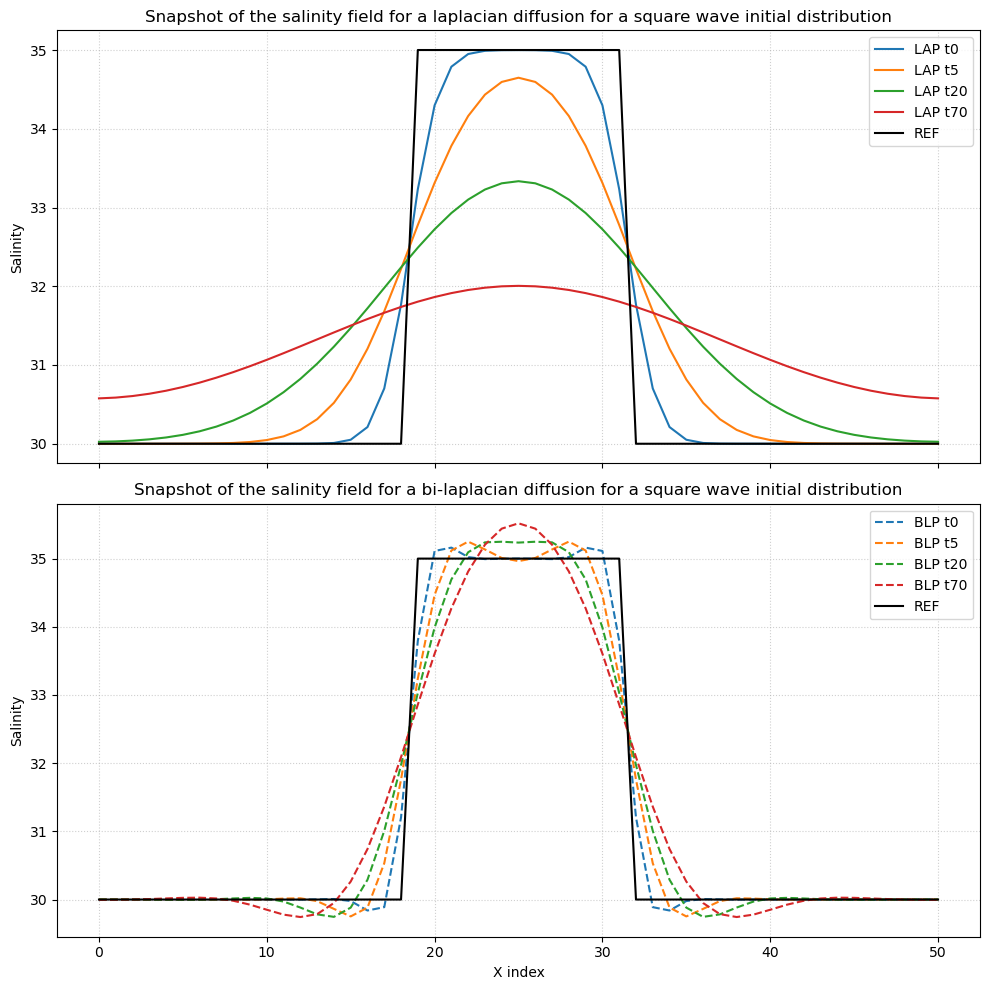

In [11]:
time_indices = [0, 5, 20, 70]
configs = [
    (lap_test, 'LAP', 'laplacian', '-'),
    (blp_test, 'BLP', 'bi-laplacian', '--')
]


fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True)


for ax, (data, prefix, diff_type, ls) in zip(axes, configs):

    sliced_data = data.isel(y_grid_T=25, deptht=0)
    

    for t in time_indices:
        ax.plot(sliced_data.isel(time_counter=t), linestyle=ls, label=f'{prefix} t{t}')
    

    ax.plot(ref, color='black', linestyle='-', label='REF', linewidth=1.5)

    ax.set_title(f'Snapshot of the salinity field for a {diff_type} diffusion for a square wave initial distribution')
    ax.set_ylabel('Salinity')
    ax.legend(loc='upper right')
    ax.grid(True, linestyle=':', alpha=0.6)

axes[1].set_xlabel('X index')
plt.tight_layout()
plt.show()

Overshoot/undershoot for bilaplacian and not for laplacian.